# Yang 2025: decoding a budgerigar's own voice from its vocal-motor cortex

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/urancon/deepSTRF/blob/develop/examples/explore_yang2025_decoding.ipynb)

This notebook introduces deepSTRF's **decoding** API on the
[Yang 2025](../md/README_Yang_2025.md) dataset (Yang & Long, 2025): single units
in the anterior arcopallium (AAC) of budgerigars, recorded while the birds sing
warble and produce calls, together with the bird's own voice picked up by a
piezo microphone on the skull.

AAC is a vocal-*motor* area: its activity precedes the sound. So instead of
predicting neurons from sound (encoding), we predict the **sound's
spectrogram from the neurons** (decoding). We will

1. load the dataset and look at one warble bout,
2. fit a linear decoder (Wiener filter) on one bird,
3. compare it to a control that ignores the neural data.

## Setup — Google Colab

On Colab the cell below installs deepSTRF from source; on a local install it does nothing.

**Data credit**: Yang, Z. & Long, M. A. (2025). Convergent vocal representations
in parrot and human forebrain motor networks. *Nature* 640, 427–434.
Data on [Zenodo](https://doi.org/10.5281/zenodo.14057061) under CC BY 4.0.

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip install -q git+https://github.com/urancon/deepSTRF.git@develop
    print("deepSTRF installed from GitHub.")
else:
    print("Local environment — assuming deepSTRF is already importable.")

Local environment — assuming deepSTRF is already importable.


## 1. Load the dataset

`download=True` fetches only the needed files (about 3.3 GB) from the 15.7 GB
Zenodo archive, then builds a ~100 MB cache of the vocal episodes. Each item is
one warble bout or call (bouts longer than 5 s are cut into pieces), starting
300 ms before the vocal onset.

In [2]:
import collections
import warnings
warnings.filterwarnings("ignore", message="IProgress not found")   # tqdm in a plain kernel

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch.utils.data import DataLoader

from deepSTRF.datasets.audio import Yang2025Dataset
from deepSTRF.utils import neural_collate

ds = Yang2025Dataset(download=True)
print(ds)
print(f"{ds.N_neurons} neurons, {len(ds.stims)} items, F = {ds.F} mel bands, dt = {ds.dt} ms")
count = collections.Counter((m['bird'], m['episode_type'], m['split']) for m in ds.stim_meta)
for bird in ds.birds:
    n_units = sum(m['bird'] == bird for m in ds.nrn_meta)
    print(f"{bird:6s} {n_units:3d} units | " + " | ".join(
        f"{s}: {count[(bird, 'warble', s)]} warble + {count[(bird, 'call', s)]} calls"
        for s in ('train', 'val', 'test')))

Yang2025Dataset(N_neurons=220, selected=0, N_stims=467, dt_ms=5.0)
220 neurons, 467 items, F = 32 mel bands, dt = 5.0 ms
Ti81    49 units | train: 61 warble + 26 calls | val: 12 warble + 8 calls | test: 11 warble + 6 calls
Li145   81 units | train: 40 warble + 37 calls | val: 6 warble + 14 calls | test: 8 warble + 9 calls
Bl122   43 units | train: 49 warble + 18 calls | val: 12 warble + 5 calls | test: 15 warble + 4 calls
Or61    47 units | train: 54 warble + 29 calls | val: 10 warble + 7 calls | test: 19 warble + 7 calls


## 2. One warble bout

Top: the decoding *target*, the log-mel spectrogram of the bird's voice.
Bottom: the decoder *input*, spike counts of the bird's 49 simultaneously
recorded units (one row per unit).

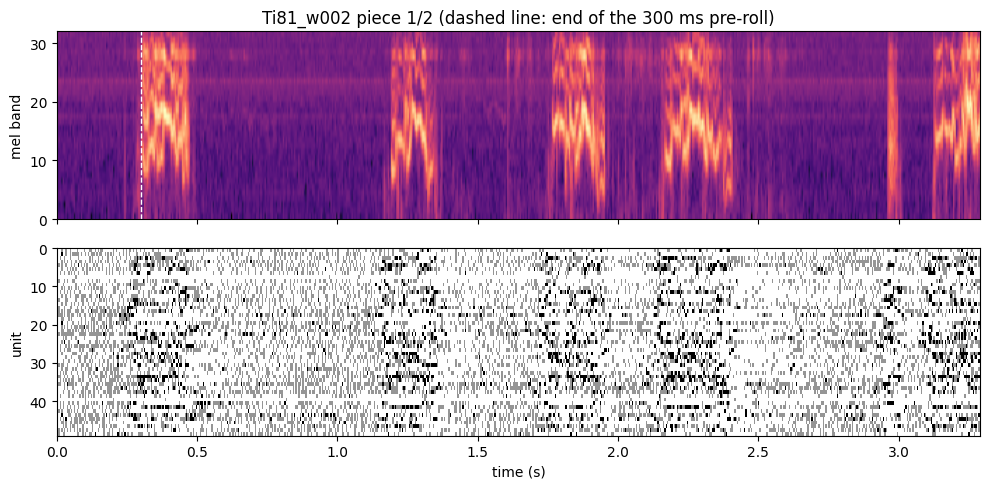

In [3]:
s = next(i for i, m in enumerate(ds.stim_meta)
         if m['bird'] == 'Ti81' and m['episode_type'] == 'warble' and m['n_pieces'] > 1)
meta = ds.stim_meta[s]
units = [n for n, m in enumerate(ds.nrn_meta) if m['bird'] == meta['bird']]
spikes = torch.cat([ds.responses[s][n] for n in units]).numpy()
spec = ds.stims[s][0].numpy()
t = np.arange(spec.shape[-1]) * ds.dt / 1000

fig, (a0, a1) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
a0.imshow(spec, origin='lower', aspect='auto', cmap='magma', extent=[0, t[-1], 0, ds.F])
a0.axvline(meta['vocal_onset_s'] - meta['t_start_s'], color='w', ls='--', lw=1)
a0.set_ylabel('mel band')
a0.set_title(f"{meta['bout_id']} piece {meta['piece_idx'] + 1}/{meta['n_pieces']} "
             f"(dashed line: end of the 300 ms pre-roll)")
a1.imshow(spikes, aspect='auto', cmap='Greys', interpolation='nearest',
          extent=[0, t[-1], len(units), 0], vmax=2)
a1.set_ylabel('unit'); a1.set_xlabel('time (s)')
plt.tight_layout(); plt.show()

## 3. A linear decoder on one bird

Each bird is a separate population, so we fit one decoder per bird. The dataset
ships a fixed train / val / test split (`stim_meta['split']`) that keeps every
bout in a single split.

The `WienerFilter` predicts each mel band as a weighted sum of all units'
activity over the last `n_lags` bins (here 20 bins = 100 ms; it is causal, as
suits a motor area). It is fit in closed form by ridge regression; we choose the
ridge strength on the validation split.

In [4]:
from deepSTRF.models.audio.decoding import WienerFilter, MeanTargetBaseline, valid_time_mask
from deepSTRF.metrics import spectrogram_corrcoef

def subset(split, bird='Ti81'):
    d = Yang2025Dataset(download=True)
    d.select_pop_by_nrn_attr('bird', bird)
    d.select_stims_by_attr('split', split)
    return d

def evaluate(model, d):
    """Per-band Pearson r of the log-mel over all (unpadded) frames, averaged over bands."""
    b = next(iter(DataLoader(d, batch_size=len(d), collate_fn=neural_collate)))
    with torch.no_grad():
        pred = model(b['responses'])
    mask = valid_time_mask(b['responses'])[:, None, None, :]
    return float(spectrogram_corrcoef(pred, b['stims'], mask=mask)), pred, b

train, val, test = subset('train'), subset('val'), subset('test')
N, F = train.n_selected, train.F
train_loader = DataLoader(train, batch_size=8, collate_fn=neural_collate)

scores = {}
for alpha in (1e2, 1e3, 1e4, 1e5, 1e6):
    scores[alpha] = evaluate(WienerFilter(N, F, n_lags=20).fit(train_loader, alpha=alpha), val)[0]
    print(f"alpha {alpha:8.0e}: val r = {scores[alpha]:.3f}")
alpha = max(scores, key=scores.get)

wiener = WienerFilter(N, F, n_lags=20).fit(train_loader, alpha=alpha)
control = MeanTargetBaseline(N, F).fit(train_loader)
r_w, pred_w, batch = evaluate(wiener, test)
r_c, _, _ = evaluate(control, test)
print(f"\nTest set ({len(test)} items):  Wiener r = {r_w:.3f}   |   control (no neural input) r = {r_c:.3f}")

alpha    1e+02: val r = 0.718


alpha    1e+03: val r = 0.718


alpha    1e+04: val r = 0.712


alpha    1e+05: val r = 0.664


alpha    1e+06: val r = 0.583



Test set (17 items):  Wiener r = 0.720   |   control (no neural input) r = 0.178


The control predicts the average training spectrogram aligned on item onset;
it captures only what is common to all items (the mean spectrum, and the silent
pre-roll followed by sound). The gap between the two is what the neural activity
tells the decoder about *this* vocalisation.

## 4. Decoded vs. true spectrogram

A test warble item, with the Wiener filter's reconstruction below the target.

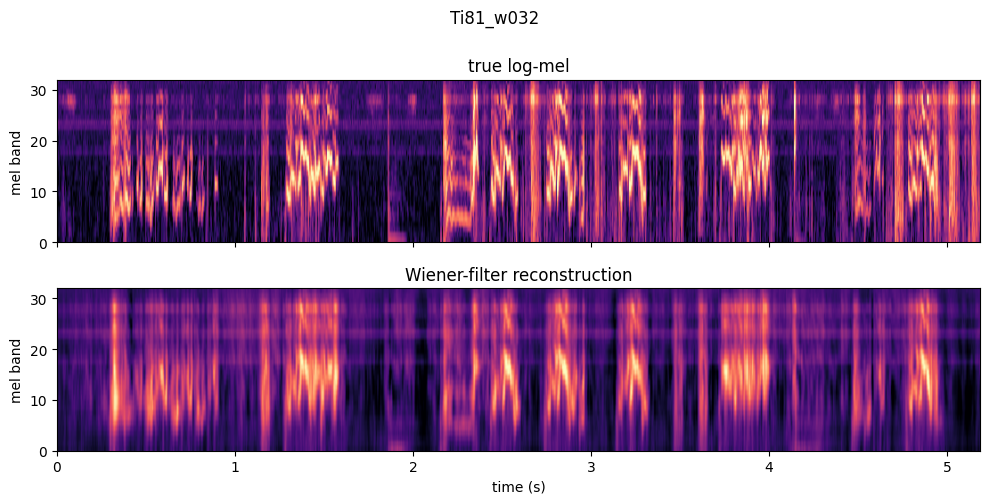

In [5]:
i = max((k for k, m in enumerate(batch['stim_meta']) if m['episode_type'] == 'warble'),
        key=lambda k: batch['stim_meta'][k]['duration_s'])
T = int(valid_time_mask(batch['responses'])[i].sum())
true, rec = batch['stims'][i, 0, :, :T].numpy(), pred_w[i, 0, :, :T].numpy()
vmin, vmax = np.percentile(true, [2, 99.5])
fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, sharey=True)
ext = [0, T * ds.dt / 1000, 0, F]
for ax, x, title in zip(axes, (true, rec), ('true log-mel', 'Wiener-filter reconstruction')):
    ax.imshow(x, origin='lower', aspect='auto', cmap='magma', vmin=vmin, vmax=vmax, extent=ext)
    ax.set_title(title); ax.set_ylabel('mel band')
axes[1].set_xlabel('time (s)')
plt.suptitle(batch['stim_meta'][i]['bout_id'], y=1.0)
plt.tight_layout(); plt.show()

## Next steps

- Any `AudioDecodingModel` subclass (a recurrent decoder, for instance) trains with
  `deepSTRF.training.Fitter` as usual; the Fitter reads `model.direction` and
  swaps input and target. See the [Decoding](../md/decoding.md) page.
- `deepSTRF.metrics.mel_cepstral_distortion` gives a second, spectral-shape
  measure of reconstruction quality.